# NB01 — `wcprop`: low-energy physics in water

`wcprop` propagates primary particles with Geant4 in an infinite volume of pure water (`production/atmospheric/geant4/wcprop`). It does not track optical photons: for every charged step it adds the mean Cherenkov yield (n = 1.333, 300–600 nm) to 10 ns time bins. It also stores the truth of neutron captures and of every μ± / π± that stops.

This notebook checks the low-energy physics that the atmospheric backgrounds of the DSNB search depend on:

| Sample | Primaries | What it tests |
|---|---|---|
| `ecal` | e⁻, 5–80 MeV, 200 per energy | light yield and energy resolution |
| `mup` | μ⁺, kinetic energy 1–50 MeV (invisible) | lifetime, Michel spectrum |
| `mum` | μ⁻, same | capture on ¹⁶O, binding to H |
| `pip`, `pim` | π±, 30 MeV | fate at rest |
| `ncqe` | 6.18 MeV γ + 10 MeV n | neutron capture on H |

The samples are produced by `validation/g4_lowe_checks.py` (Geant4 11.0.3, `QGSP_BIC_HP` + thermal neutrons) and read here from `data/g4checks/`:

```bash
python validation/g4_lowe_checks.py production/atmospheric/geant4/wcprop/build/wcprop data/g4checks
```

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hk_sunu_sim import g4out, response
from hk_sunu_sim.plotting import INK, MUTED, SERIES, stair, style, use_style

use_style()
DATA = Path("../data/g4checks")
ELECTRON_E = [5, 10, 15, 20, 30, 40, 50, 60, 80]   # as in g4_lowe_checks.py
read = lambda name: g4out.read(DATA / name)

## 1. Electron light yield and energy resolution

The visible-energy proxy is the number of Cherenkov photons of the prompt light cluster. It must be linear in the electron energy: its slope `k` (photons per MeV) is the calibration used by `response.PHOTONS_PER_MEV`.

k = 165.2 photons/MeV (response.PHOTONS_PER_MEV = 165.2)


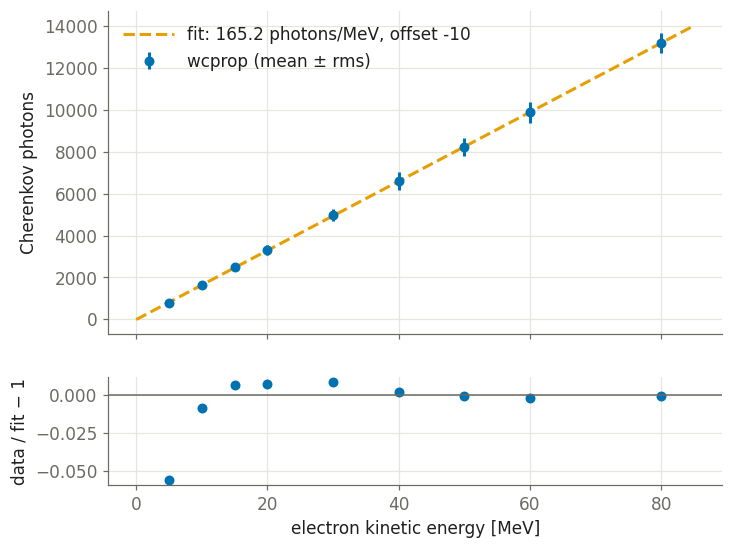

In [2]:
light, _, _ = read("ecal")
p = g4out.clusters(light).query("rank == 0").copy()
p["E"] = np.array(ELECTRON_E)[p.event_id // 1000]
m = p.groupby("E")["n"].agg(["mean", "std", "count"])
k, b = np.polyfit(m.index, m["mean"], 1)

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7.2, 5.6), sharex=True, height_ratios=[3, 1])
ax.errorbar(m.index, m["mean"], m["std"], ls="none", marker="o", color=SERIES[0], label="wcprop (mean ± rms)")
x = np.linspace(0, 85, 10)
ax.plot(x, k * x + b, **style(1), label=f"fit: {k:.1f} photons/MeV, offset {b:.0f}")
ax.set_ylabel("Cherenkov photons")
ax.legend()
ax2.plot(m.index, m["mean"] / (k * m.index + b) - 1, ls="none", marker="o", color=SERIES[0])
ax2.axhline(0, color=MUTED, lw=1)
ax2.set_ylabel("data / fit − 1")
ax2.set_xlabel("electron kinetic energy [MeV]")
print(f"k = {k:.1f} photons/MeV (response.PHOTONS_PER_MEV = {response.PHOTONS_PER_MEV})")

The resolution follows from the response chain without any tuning: Geant4 light-yield fluctuations plus Poisson photostatistics at `pe_per_mev` = 6 (SK-IV order of magnitude). It is compared with the SK-IV parametrisation σ = −0.084 + 0.349√E + 0.040E (MeV), quoted from memory, **to be checked in the source**.

,mean,std,sigma_over_e
E,,,
5,4.648,1.022,0.220
10,9.882,1.538,0.156
15,15.092,1.794,0.119
20,19.912,2.285,0.115
30,30.262,2.959,0.098
40,40.061,3.823,0.095
50,49.544,3.858,0.078
60,60.225,4.672,0.078
80,80.174,4.764,0.059


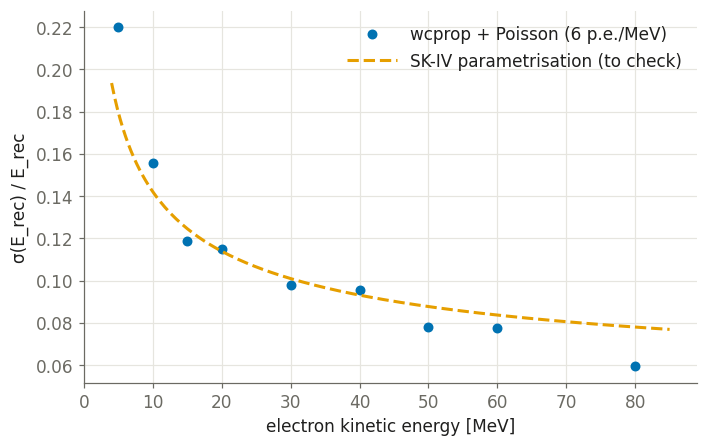

In [3]:
rng = np.random.default_rng(1)
p["e_rec"] = response.energy(p["n"], response.SK4, rng)
r = p.groupby("E")["e_rec"].agg(["mean", "std"])
e = np.linspace(4, 85, 200)
sk4 = (-0.084 + 0.349 * np.sqrt(e) + 0.040 * e) / e

fig, ax = plt.subplots()
ax.plot(r.index, r["std"] / r["mean"], ls="none", marker="o", color=SERIES[0], label="wcprop + Poisson (6 p.e./MeV)")
ax.plot(e, sk4, **style(1), label="SK-IV parametrisation (to check)")
ax.set_xlabel("electron kinetic energy [MeV]")
ax.set_ylabel("σ(E_rec) / E_rec")
ax.legend()
r.assign(sigma_over_e=r["std"] / r["mean"]).round(3)

Agreement within ~10 % between 10 and 60 MeV; at 5 MeV ours is ~20 % wider. At 80 MeV ours is narrower: detector effects (PMT saturation, reconstruction) are missing. The DSNB window (8–80 MeV, signal mostly < 30 MeV) is in the well-described part.

## 2. μ⁺ at rest: lifetime and Michel spectrum

The μ⁺ is repelled by nuclei, so it always decays: this is the cleanest check of the decay-electron (Michel) spectrum, the dominant atmospheric background in 16–50 MeV. The theoretical spectrum of a free muon, neglecting the electron mass and radiative corrections, is dN/dx = 2x²(3 − 2x), with x = E_e / W and W = 52.83 MeV.

tau = 2187 +- 46 ns (PDG 2197 ns); <E> = 36.9 MeV (tree level 37 MeV)


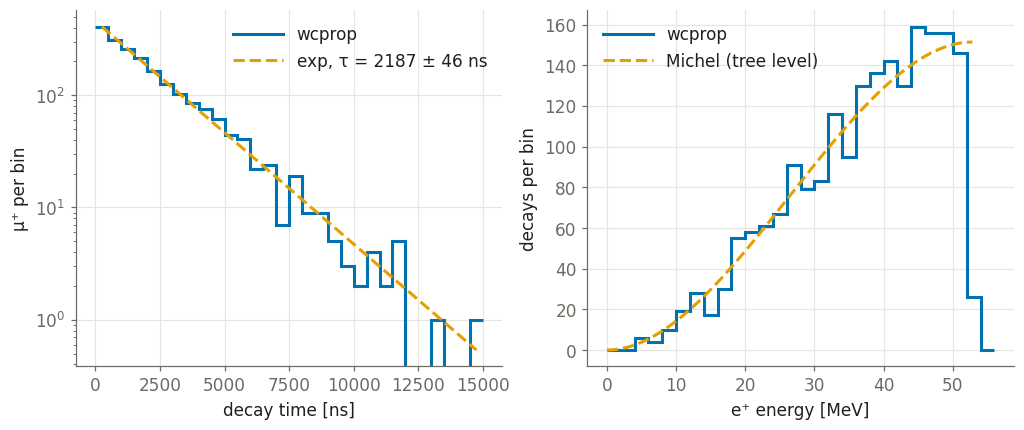

In [4]:
_, _, ends = read("mup")
d = ends.query("parent_id == 0")
tau = d.t.mean()
tau_err = d.t.std() / np.sqrt(len(d))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
bins = np.linspace(0, 15000, 31)
h, _ = np.histogram(d.t, bins)
stair(ax, h, bins, color=SERIES[0], ls="-", label="wcprop")
c = 0.5 * (bins[1:] + bins[:-1])
ax.plot(c, len(d) * np.diff(bins) / tau * np.exp(-c / tau), **style(1), label=f"exp, τ = {tau:.0f} ± {tau_err:.0f} ns")
ax.set_yscale("log")
ax.set_xlabel("decay time [ns]")
ax.set_ylabel("μ⁺ per bin")
ax.legend()

W = 52.83
bins = np.linspace(0, 56, 29)
h, _ = np.histogram(d.e_charged, bins)
stair(ax2, h, bins, color=SERIES[0], ls="-", label="wcprop")
x = np.linspace(0, 1, 200)
ax2.plot(x * W, len(d) * (bins[1] - bins[0]) / W * 2 * x**2 * (3 - 2 * x), **style(1), label="Michel (tree level)")
ax2.set_xlabel("e⁺ energy [MeV]")
ax2.set_ylabel("decays per bin")
ax2.legend(loc="upper left")
print(f"tau = {tau:.0f} +- {tau_err:.0f} ns (PDG 2197 ns); <E> = {d.e_charged.mean():.1f} MeV (tree level 37 MeV)")

## 3. μ⁻ at rest: capture on ¹⁶O and the hydrogen problem

A stopped μ⁻ forms a muonic atom. On ¹⁶O it either decays (Michel) or is captured, μ⁻ p → ν n, which gives no Michel. Reference values in water: capture fraction 0.184 and mean lifetime 1795 ns.

Geant4 11.0 binds ~30 % of the stopped μ⁻ to **hydrogen** and does not transfer the μp atom to oxygen. In real water the transfer happens and all μ⁻ end on O. The nucleus is stored as `target_z`; `g4out.hydrogen_binding_weights` gives weight 0 to the events bound to H and 1/f_O to the rest.

In [5]:
_, ncap_mum, ends = read("mum")
d = ends.query("parent_id == 0")
o = d[d.target_z == 8]
w = g4out.hydrogen_binding_weights(ends)
dw = d.assign(w=d.event_id.map(w))

rows = [
    ("stops bound to H", (d.target_z == 1).mean(), "≈ 0"),
    ("capture fraction, all (raw Geant4)", (d.fate == "capture").mean(), "0.184"),
    ("capture fraction, on O", (o.fate == "capture").mean(), "0.184"),
    ("capture fraction, weighted", np.average(dw.fate == "capture", weights=dw.w), "0.184"),
    ("mean time on O [ns]", o.t.mean(), "1795"),
    ("neutrons per capture on O", o[o.fate == "capture"].n_neutron.mean(), "to check"),
]
pd.DataFrame(rows, columns=["quantity", "wcprop", "reference"]).round(3)

,quantity,wcprop,reference
0,stops bound to H,0.303,≈ 0
1,"capture fraction, all (raw Geant4)",0.140,0.184
2,"capture fraction, on O",0.200,0.184
3,"capture fraction, weighted",0.200,0.184
4,mean time on O [ns],1777.268,1795
5,neutrons per capture on O,1.487,to check


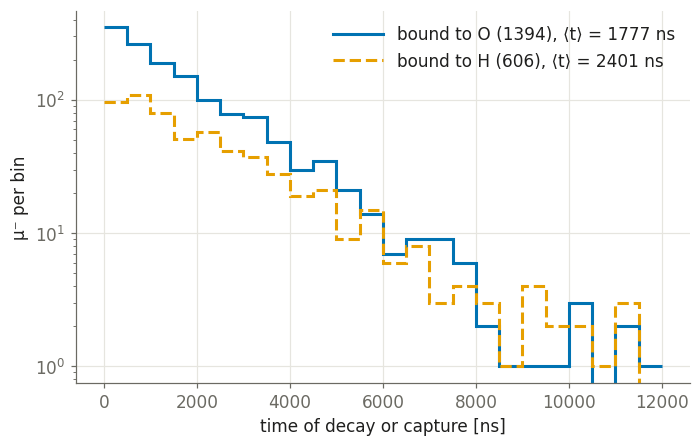

In [6]:
fig, ax = plt.subplots()
bins = np.linspace(0, 12000, 25)
for i, (z, lab) in enumerate([(8, "bound to O"), (1, "bound to H")]):
    s = d[d.target_z == z]
    h, _ = np.histogram(s.t, bins)
    stair(ax, h, bins, **style(i), label=f"{lab} ({len(s)}), ⟨t⟩ = {s.t.mean():.0f} ns")
ax.set_yscale("log")
ax.set_xlabel("time of decay or capture [ns]")
ax.set_ylabel("μ⁻ per bin")
ax.legend();

On O, Geant4 reproduces the capture fraction and the lifetime. The μ⁻ bound to H behave as free muons (no capture, τ ≈ 2.2 μs): without the weights the Michel yield of μ⁻ would be ~7 % too high. This matters for the invisible-muon (decay-e) background.

## 4. π± at rest

A stopped π⁺ decays (π⁺ → μ⁺ → e⁺, so it adds to the decay electrons). A stopped π⁻ is absorbed by the nucleus through the strong interaction and gives neutrons and γ, but no Michel. A few % of the 30 MeV pions interact in flight before stopping (`inelastic`).

In [7]:
rows = {}
for name in ["pip", "pim"]:
    _, _, ends = read(name)
    d = ends.query("parent_id == 0")
    rows[name] = d.fate.value_counts(normalize=True)
    if name == "pim":
        stops = d[d.fate != "inelastic"]
        print(f"pi- stops bound to H: {(stops.target_z == 1).mean():.3f}")
pd.DataFrame(rows).fillna(0).round(3)

pi- stops bound to H: 0.313


,pip,pim
fate,,
absorption,0.000,0.970
decay,0.991,0.005
inelastic,0.009,0.025


Geant4 also binds stopped π⁻ to H, where π⁻p → π⁰n / nγ follows: unphysical in water. The same event weights correct it.

## 5. Neutron capture on hydrogen

The `ncqe` sample (a 6.18 MeV γ plus a 10 MeV neutron) tests the delayed signal that neutron tagging looks for: a 2.224 MeV γ from n + p → d, with τ ≈ 204 μs in water. The time constant is fitted for t > 20 μs, after thermalisation.

captures per neutron: 0.887; on H: 1.000
tau = 211 +- 7 us (ref. ~204 us); E_gamma = 2.2244 MeV (2.2233 after deuteron recoil)
distance from vertex: median 20 cm, 90 % below 41 cm


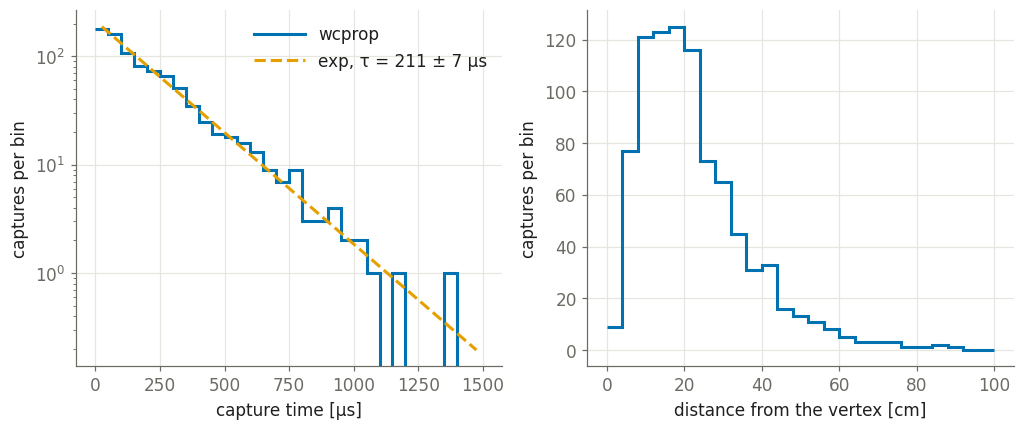

In [8]:
_, ncap, _ = read("ncqe")
h1 = ncap[ncap.target_z == 1]
t_us = h1.t / 1e3
t0 = 20.0
tail = t_us[t_us > t0]
tau_n = (tail - t0).mean()
tau_n_err = tau_n / np.sqrt(len(tail))
r = np.sqrt(h1.x**2 + h1.y**2 + h1.z**2)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
bins = np.linspace(0, 1500, 31)
h, _ = np.histogram(t_us, bins)
stair(ax, h, bins, color=SERIES[0], ls="-", label="wcprop")
c = 0.5 * (bins[1:] + bins[:-1])
ax.plot(c, len(tail) * np.diff(bins) / tau_n * np.exp(-(c - t0) / tau_n), **style(1),
        label=f"exp, τ = {tau_n:.0f} ± {tau_n_err:.0f} μs")
ax.set_yscale("log")
ax.set_xlabel("capture time [μs]")
ax.set_ylabel("captures per bin")
ax.legend()
bins = np.linspace(0, 100, 26)
h, _ = np.histogram(r, bins)
stair(ax2, h, bins, color=SERIES[0], ls="-")
ax2.set_xlabel("distance from the vertex [cm]")
ax2.set_ylabel("captures per bin")

print(f"captures per neutron: {len(ncap) / 1000:.3f}; on H: {len(h1) / len(ncap):.3f}")
print(f"tau = {tau_n:.0f} +- {tau_n_err:.0f} us (ref. ~204 us); E_gamma = {h1.e_gamma.mean():.4f} MeV (2.2233 after deuteron recoil)")
print(f"distance from vertex: median {r.median():.0f} cm, 90 % below {r.quantile(0.9):.0f} cm")

- τ and E_γ agree with the reference values.
- Only ~89 % of the 10 MeV neutrons are captured. The likely reason is reactions on ¹⁶O before thermalisation ((n,α), (n,p), open above a few MeV), which remove the neutron. **To check** in the Geant4 output; it matters for the neutron multiplicity of NCQE events, whose knocked-out nucleons have tens of MeV.
- The capture point is a median 20 cm from the vertex (90 % within ~40 cm), well below the vertex resolution at 2.2 MeV in SK (~1 m): the tag window cut on distance is not limited by neutron transport.

## 6. Summary

| Check | Status |
|---|---|
| e⁻ light yield linear, 5–80 MeV | ✓ (calibration `k`) |
| Energy resolution vs SK-IV | ✓ within ~10 % for 10–60 MeV (~20 % wider at 5 MeV); SK-IV formula to verify |
| μ⁺ lifetime and Michel spectrum | ✓ |
| μ⁻ capture fraction and lifetime on O | ✓ on O; **H binding corrected with weights** |
| π± at rest | ✓ on O; π⁻ on H unphysical, same weights |
| n capture on H: τ, E_γ | ✓ (E_γ 1 keV high, irrelevant) |
| n capture probability of fast neutrons | **to understand** (~89 % at 10 MeV) |